# Long Short-Term Memory (LSTM)

---

## Key Definitions

| Term | Definition |
|------|-----------|
| **LSTM** | A special type of RNN that can learn long-term dependencies using gates and a cell state |
| **Vanishing Gradient** | When gradients become too small during backpropagation, preventing the model from learning long-range patterns |
| **Exploding Gradient** | When gradients become too large, causing unstable training (NaN values) |
| **Cell State** | A "highway" that carries long-term memory through the network with minimal changes |
| **Hidden State** | Short-term memory that acts as the output at each time step |
| **Forget Gate** | Decides what old information to throw away from the cell state (σ → 0 = forget, 1 = keep) |
| **Input Gate** | Decides what new information to store in the cell state |
| **Output Gate** | Decides what part of the cell state to output as the hidden state |
| **Sigmoid (σ)** | Activation function that outputs 0-1, used in gates as a "how much to pass through" controller |
| **tanh** | Activation function that outputs -1 to 1, used to create candidate values |

---

## Problem: Vanishing & Exploding Gradients

**Why vanilla RNN fails on long sequences:**

| Problem | What happens | Example |
|---------|-------------|----------|
| Vanishing gradient | Gradients → 0 during backprop | "The cat, which sat on the mat, **was** sleeping" — RNN forgets "cat" by the time it reaches "was" |
| Exploding gradient | Gradients → ∞ during backprop | Weights blow up, model outputs NaN |

**Why?** In backpropagation through time, gradients are multiplied at each step:
```
gradient = W × W × W × W × ... × W   (one W per time step)

If |W| < 1  →  gradient shrinks to 0     (vanishing)
If |W| > 1  →  gradient explodes to ∞    (exploding)
```

**Result:** RNN can't learn dependencies more than ~10 steps apart.

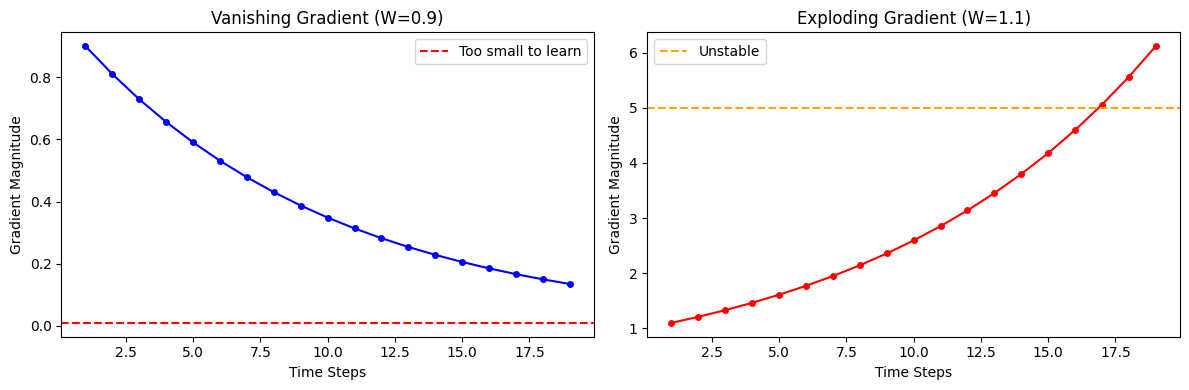

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Visual: how gradients vanish/explode over time steps
steps = np.arange(1, 20)
vanish = 0.9 ** steps
explode = 1.1 ** steps

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(steps, vanish, 'b-o', markersize=4)
ax1.set_title('Vanishing Gradient (W=0.9)')
ax1.set_xlabel('Time Steps'); ax1.set_ylabel('Gradient Magnitude')
ax1.axhline(y=0.01, color='r', linestyle='--', label='Too small to learn')
ax1.legend()

ax2.plot(steps, explode, 'r-o', markersize=4)
ax2.set_title('Exploding Gradient (W=1.1)')
ax2.set_xlabel('Time Steps'); ax2.set_ylabel('Gradient Magnitude')
ax2.axhline(y=5, color='orange', linestyle='--', label='Unstable')
ax2.legend()
plt.tight_layout()
plt.show()

## LSTM Solution

LSTM adds a **cell state** (highway) that lets information flow unchanged across many time steps.

```
RNN:   h(t) = tanh(W·[h(t-1), x(t)])         ← single path, gradient shrinks

LSTM:  Cell state flows through with only + and × operations  ← gradient preserved!
```

## LSTM Cell Architecture

```
                    Cell State (C_t) — the "highway"
     ┌──────────────────────────────────────────────────┐
     │              ×              +                     │
     │              │              │                     ↓
     │         ┌────┴────┐   ┌────┴────┐          ┌─────────┐
     │         │ FORGET  │   │  INPUT   │          │ OUTPUT  │
     │         │  GATE   │   │  GATE    │          │  GATE   │
     │         └────┬────┘   └────┬────┘          └────┬────┘
     │              │              │                    │
     └──────── h(t-1), x(t) ──────┘                   ↓
                                                     h(t)
```

### 3 Gates (all are sigmoid → output between 0 and 1)

| Gate | Formula | What it does | Analogy |
|------|---------|-------------|----------|
| **Forget** | f = σ(W_f·[h(t-1), x(t)]) | Decides what to **throw away** from cell state | Erasing old notes |
| **Input** | i = σ(W_i·[h(t-1), x(t)]) | Decides what **new info** to store | Writing new notes |
| **Output** | o = σ(W_o·[h(t-1), x(t)]) | Decides what to **output** as hidden state | Reading from notes |

### Step-by-step:
```
1. Forget:   f(t) = σ(W_f · [h(t-1), x(t)])        → what to delete?
2. Input:    i(t) = σ(W_i · [h(t-1), x(t)])        → what to add?
             C̃(t) = tanh(W_c · [h(t-1), x(t)])     → candidate new info
3. Update:   C(t) = f(t) × C(t-1) + i(t) × C̃(t)   → new cell state
4. Output:   o(t) = σ(W_o · [h(t-1), x(t)])        → what to show?
             h(t) = o(t) × tanh(C(t))               → new hidden state
```

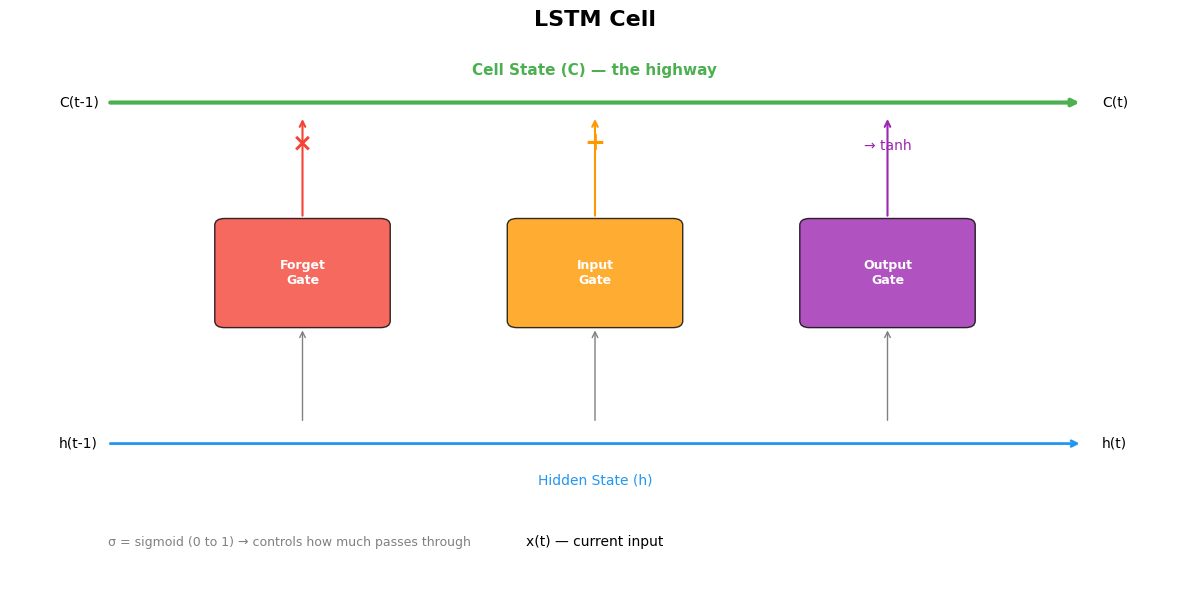

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(1, 1, figsize=(12, 6))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis('off')
ax.set_title('LSTM Cell', fontsize=16, fontweight='bold')

# Cell state line (highway)
ax.annotate('', xy=(11, 7), xytext=(1, 7), arrowprops=dict(arrowstyle='->', lw=3, color='#4CAF50'))
ax.text(6, 7.4, 'Cell State (C) — the highway', ha='center', fontsize=11, color='#4CAF50', fontweight='bold')

# Hidden state line
ax.annotate('', xy=(11, 2), xytext=(1, 2), arrowprops=dict(arrowstyle='->', lw=2, color='#2196F3'))
ax.text(6, 1.4, 'Hidden State (h)', ha='center', fontsize=10, color='#2196F3')

# Gates
gates = [('Forget\nGate', 3, '#F44336'), ('Input\nGate', 6, '#FF9800'), ('Output\nGate', 9, '#9C27B0')]
for name, x, color in gates:
    rect = mpatches.FancyBboxPatch((x-0.8, 3.8), 1.6, 1.4, boxstyle='round,pad=0.1',
                                    facecolor=color, alpha=0.8)
    ax.add_patch(rect)
    ax.text(x, 4.5, name, ha='center', va='center', fontsize=9, color='white', fontweight='bold')
    # Arrow from gate to cell state
    ax.annotate('', xy=(x, 6.8), xytext=(x, 5.3), arrowprops=dict(arrowstyle='->', color=color, lw=1.5))
    # Arrow from hidden state to gate
    ax.annotate('', xy=(x, 3.7), xytext=(x, 2.3), arrowprops=dict(arrowstyle='->', color='gray', lw=1))

# Operations on cell state
ax.text(3, 6.3, '×', fontsize=18, ha='center', color='#F44336', fontweight='bold')
ax.text(6, 6.3, '+', fontsize=18, ha='center', color='#FF9800', fontweight='bold')
ax.text(9, 6.3, '→ tanh', fontsize=10, ha='center', color='#9C27B0')

# Labels
ax.text(0.5, 7, 'C(t-1)', fontsize=10, va='center')
ax.text(11.2, 7, 'C(t)', fontsize=10, va='center')
ax.text(0.5, 2, 'h(t-1)', fontsize=10, va='center')
ax.text(11.2, 2, 'h(t)', fontsize=10, va='center')
ax.text(6, 0.5, 'x(t) — current input', ha='center', fontsize=10)

# Legend
ax.text(1, 0.5, 'σ = sigmoid (0 to 1) → controls how much passes through', fontsize=9, color='gray')
plt.tight_layout()
plt.show()

## Cell State vs Hidden State

| | Cell State (C) | Hidden State (h) |
|--|----------------|------------------|
| **Role** | Long-term memory | Short-term memory / output |
| **Flow** | Straight line (highway) | Modified at each step |
| **Changes** | Only × and + (gentle) | Goes through tanh + gate |
| **Used for** | Storing info across many steps | Predicting at current step |
| **Analogy** | Your notebook | What you say out loud |

**Key insight:** Cell state is why LSTM can remember info 100+ steps back — gradient flows through without shrinking!

## How LSTM Solves Long-Range Dependencies

**Example:** "The **cat**, which sat on the mat and played with the yarn, **was** sleeping"

```
RNN:  "cat" → ... 10 words ... → forgets "cat" → can't predict "was" (singular)

LSTM: "cat" → Forget gate keeps it → ... 10 words ... → still remembers "cat" → predicts "was" ✓
```

**Why?**
- Forget gate = 1 (don't forget) → cell state unchanged → info preserved
- Gradient flows through cell state highway without multiplying by W repeatedly

## LSTM vs RNN

| Feature | RNN | LSTM |
|---------|-----|------|
| Memory | Short-term only | Short + Long-term |
| Gates | None | 3 (Forget, Input, Output) |
| Cell state | No | Yes (highway) |
| Long sequences | Fails (vanishing gradient) | Works well |
| Parameters | Few | 4× more than RNN |
| Training speed | Fast | Slower |
| Use when | Short sequences (<10 steps) | Long sequences, real tasks |

**Code difference:**
```python
# RNN
model.add(SimpleRNN(64))

# LSTM — just change one line!
model.add(LSTM(64))
```


## TEXT CLASSIFICATION on LSTM


## Resources

In [1]:
# importing the necessary library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder # CONVERT CATEGORICAL TO NUMERLICAL
from sklearn.model_selection import train_test_split # TO TRAIN THE MODEL

from tensorflow.keras.preprocessing.text import Tokenizer # CONVERTS THE WORDS INTO TOKENS FORMAT
from tensorflow.keras.preprocessing.sequence import pad_sequences # ASSIGNING 0 FOR EMPTY WORDS
from tensorflow.keras.models import Sequential # THE NEURAL NETWORK MODEL
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping # TO STOP THE EPOCHS IF THERE IS NO CHANGE IN LOSS

In [2]:
# Load dataset
df = pd.read_csv("/content/nlp_intent_dataset_200.csv")

print(df.head(10))

                     text          intent
0  can you check my order    order_status
1            good morning        greeting
2               hey buddy        greeting
3    i want my money back  refund_request
4       this is defective       complaint
5    poor quality product       complaint
6     order status please    order_status
7  please refund my money  refund_request
8    i want my money back  refund_request
9                hi there        greeting


In [3]:
df['intent'].value_counts()

,count
intent,
order_status,50
greeting,50
refund_request,50
complaint,50


In [4]:
#Encode Target Labels
label_encoder = LabelEncoder()
df['intent_encoded'] = label_encoder.fit_transform(df['intent'])

In [5]:
df['intent_encoded']

,intent_encoded
0,2
1,1
2,1
3,3
4,0
...,...
195,0
196,1
197,2
198,3


In [6]:
y = df['intent_encoded']
#complaint → 0
#greeting → 1
#order_status → 2
#refund_request → 3

In [7]:
y

,intent_encoded
0,2
1,1
2,1
3,3
4,0
...,...
195,0
196,1
197,2
198,3


In [8]:
#Tokenization (Text → Numbers)
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df['text'])

X_sequences = tokenizer.texts_to_sequences(df['text'])

In [9]:
X_sequences

[[23, 16, 41, 2, 1],
 [14, 32],
 [17, 28],
 [4, 7, 2, 20, 33],
 [10, 6, 48],
 [37, 38, 5],
 [1, 21, 22],
 [22, 3, 2, 20],
 [4, 7, 2, 20, 33],
 [25, 34],
 [49, 6, 2, 1],
 [3, 2, 1],
 [15, 11, 3],
 [13, 24],
 [4, 7, 8, 15, 12, 5],
 [15, 11, 3],
 [13, 24],
 [29, 11, 3],
 [13, 2, 1],
 [56, 2, 1, 57],
 [4, 7, 8, 58, 9, 59],
 [14, 32],
 [12, 18, 6, 19],
 [1, 39],
 [1, 21, 22],
 [1, 21, 22],
 [50, 51, 2, 1, 52],
 [1, 60, 61],
 [4, 63, 30, 64],
 [42, 43, 26, 10, 5],
 [35, 8, 36, 16],
 [27],
 [1, 39],
 [23, 16, 41, 2, 1],
 [22, 3, 2, 20],
 [5, 6, 30, 40],
 [53, 54, 26, 12, 5],
 [12, 18, 6, 19],
 [4, 7, 9, 3],
 [13, 2, 1],
 [4, 7, 8, 55, 2, 1, 21],
 [22, 3, 2, 20],
 [27, 34],
 [17, 28],
 [37, 38, 5],
 [3, 2, 1],
 [27, 34],
 [17],
 [12, 18, 6, 19],
 [1, 39],
 [37, 38, 5],
 [4, 7, 9, 3],
 [27, 34],
 [10, 6, 48],
 [10, 5, 6, 31],
 [13, 2, 1],
 [12, 18, 6, 19],
 [13, 24],
 [4, 7, 9, 3],
 [13, 24],
 [3, 2, 1],
 [49, 6, 2, 1],
 [14, 44],
 [14, 65],
 [35, 8, 36, 16],
 [37, 38, 5],
 [14, 32],
 [3, 62],


In [10]:
# Padding (Make Equal Length Sequences)
max_len = max(len(seq) for seq in X_sequences)

X = pad_sequences(
    X_sequences,
    maxlen=max_len,
    padding='post'
)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)
print("Max sequence length:", max_len)


Vocabulary size: 67
Max sequence length: 7


In [11]:
# Train–Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [12]:
# Build LSTM Model
model = Sequential()

model.add(Embedding(
    input_dim=vocab_size,
    output_dim=50,
    input_length=max_len
))

model.add(LSTM(64, return_sequences=False))
model.add(Dropout(0.3))

model.add(Dense(32, activation='relu'))
model.add(Dense(len(label_encoder.classes_), activation='softmax'))

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [13]:
# Train the Model (With Early Stopping)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=12,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.3047 - loss: 1.3841 - val_accuracy: 0.3125 - val_loss: 1.3825
Epoch 2/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3984 - loss: 1.3712 - val_accuracy: 0.2500 - val_loss: 1.3723
Epoch 3/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4844 - loss: 1.3515 - val_accuracy: 0.3750 - val_loss: 1.3499
Epoch 4/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5156 - loss: 1.2971 - val_accuracy: 0.3125 - val_loss: 1.2908
Epoch 5/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5781 - loss: 1.1730 - val_accuracy: 0.3125 - val_loss: 1.1520
Epoch 6/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5938 - loss: 0.9042 - val_accuracy: 0.4375 - val_loss: 0.9588
Epoch 7/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6562 - loss: 0.6626 - val_accuracy: 0.7812 - val_loss: 0.7364
Epoch 8/12
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9141 - loss: 0.4197 - val_accuracy: 0.9375 - val_loss: 0.4261


In [14]:
# Evaluate Model Performance
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy:.2f}")

Test Accuracy: 0.98


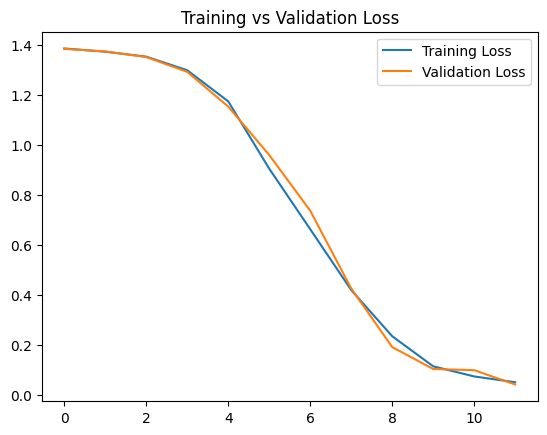

In [15]:
# Plot Training vs Validation Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()

In [16]:
# Predict Intent for New Sentences
def predict_intent(text):
    seq = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(seq, maxlen=max_len, padding='post')
    pred = model.predict(padded, verbose=0)
    intent_index = np.argmax(pred)
    return label_encoder.inverse_transform([intent_index])[0]


print(predict_intent("hello there"))
print(predict_intent("where is my order"))
print(predict_intent("this product is damaged"))
print(predict_intent("i want my money back"))

greeting
order_status
complaint
refund_request
